Device: cuda


'(MaxRetryError('HTTPSConnectionPool(host=\'huggingface.co\', port=443): Max retries exceeded with url: /datasets/jxm/nq_corpus_dpr/resolve/main/README.md (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x71283cf2bbf0>: Failed to resolve \'huggingface.co\' ([Errno -3] Temporary failure in name resolution)"))'), '(Request ID: ff1a3ad4-932a-4abf-a3b6-76a33f045433)')' thrown while requesting HEAD https://huggingface.co/datasets/jxm/nq_corpus_dpr/resolve/main/README.md
Retrying in 1s [Retry 1/5].


Embedding with GTE...
Embedding with E5...


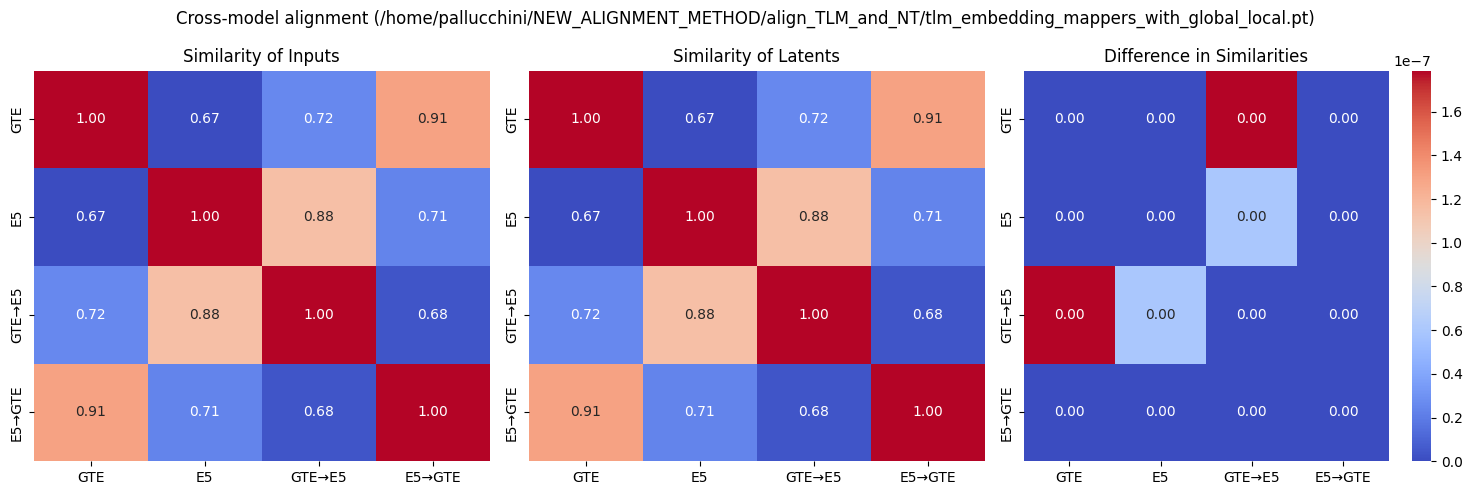

In [4]:
import torch
import torch.nn.functional as F
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel
import torch.nn as nn

# ---------------------
# Mapper definition (must match your training)
# ---------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=512, n_layers=3, n_heads=8, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim, nhead=n_heads,
            dim_feedforward=hidden_dim*4, dropout=dropout,
            activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x):
        h = self.input_proj(x.unsqueeze(1))
        h = self.transformer(h)[:, 0, :]
        return self.ln(self.output_proj(h))

# ---------------------
# Helper functions
# ---------------------
def embed_sentences(texts, tokenizer, model, device, batch_size=64):
    embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding=True, truncation=True).to(device)
        with torch.no_grad():
            out = model(**inputs)
        embs.append(out.last_hidden_state.mean(dim=1).cpu())
    return torch.cat(embs, dim=0)

def cosine_matrix(embs):
    embs = F.normalize(embs, dim=-1)
    return embs @ embs.T

def cosine_between_models(e1, e2):
    """Compute average cosine similarity across the same N samples from two models."""
    e1 = F.normalize(e1, dim=-1)
    e2 = F.normalize(e2, dim=-1)
    return (e1 * e2).sum(dim=1).mean().item()

def plot_three_heatmaps(input_mat, latent_mat, diff_mat, model_names, title_prefix):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    sns.heatmap(input_mat, annot=True, fmt=".2f", xticklabels=model_names, yticklabels=model_names,
                cmap="coolwarm", ax=axes[0], cbar=False)
    axes[0].set_title("Similarity of Inputs")

    sns.heatmap(latent_mat, annot=True, fmt=".2f", xticklabels=model_names, yticklabels=model_names,
                cmap="coolwarm", ax=axes[1], cbar=False)
    axes[1].set_title("Similarity of Latents")

    sns.heatmap(diff_mat, annot=True, fmt=".2f", xticklabels=model_names, yticklabels=model_names,
                cmap="coolwarm", ax=axes[2])
    axes[2].set_title("Difference in Similarities")

    fig.suptitle(title_prefix)
    plt.tight_layout()
    plt.show()

# ---------------------
# Main
# ---------------------
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)

    # Load dataset (Natural Questions, 1024 samples)
    dset = load_dataset("jxm/nq_corpus_dpr", split="dev", streaming=True)
    texts = [x["text"] for x in dset.take(1024)]

    # Load base models
    gte_name, e5_name = "thenlper/gte-base", "intfloat/e5-base-v2"
    gte_tok, gte_model = AutoTokenizer.from_pretrained(gte_name), AutoModel.from_pretrained(gte_name).to(device).eval()
    e5_tok, e5_model = AutoTokenizer.from_pretrained(e5_name), AutoModel.from_pretrained(e5_name).to(device).eval()

    # Get embeddings
    print("Embedding with GTE...")
    gte_embs = embed_sentences(texts, gte_tok, gte_model, device)
    print("Embedding with E5...")
    e5_embs = embed_sentences(texts, e5_tok, e5_model, device)

    # Load mapper (choose TLM or NT-XENT)
    mapper_file = "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_TLM_and_NT/tlm_embedding_mappers_with_global_local.pt"#"nt_xent_embedding_mappers.pt"   # or "tlm_embedding_mappers.pt"
    ckpt = torch.load(mapper_file, map_location="cpu")
    D = gte_embs.shape[1]

    mapper_g2e5 = TransformerEmbeddingMapper(D)
    mapper_g2e5.load_state_dict(ckpt["gte2e5"])
    mapper_g2e5.to(device).eval()

    mapper_e52g = TransformerEmbeddingMapper(D)
    mapper_e52g.load_state_dict(ckpt["e52gte"])
    mapper_e52g.to(device).eval()

    # Map embeddings
    with torch.no_grad():
        gte2e5_lat = mapper_g2e5(gte_embs.to(device)).cpu()
        e52gte_lat = mapper_e52g(e5_embs.to(device)).cpu()

    # ---------------------
    # Compute model-to-model cosine correlations
    # ---------------------
    models = {
        "GTE": gte_embs,
        "E5": e5_embs,
        "GTE→E5": gte2e5_lat,
        "E5→GTE": e52gte_lat
    }
    model_names = list(models.keys())

    # Input similarity matrix
    n = len(model_names)
    input_mat = torch.zeros((n, n))
    latent_mat = torch.zeros((n, n))
    for i in range(n):
        for j in range(n):
            input_mat[i, j] = cosine_between_models(models[model_names[i]], models[model_names[j]])
            # Compare latents only across projected spaces
            latent_mat[i, j] = cosine_between_models(
                F.normalize(models[model_names[i]], dim=-1),
                F.normalize(models[model_names[j]], dim=-1)
            )

    diff_mat = torch.abs(input_mat - latent_mat)

    # ---------------------
    # Plot results like Figure 4
    # ---------------------
    plot_three_heatmaps(input_mat, latent_mat, diff_mat, model_names,
                        title_prefix=f"Cross-model alignment ({mapper_file})")